# AfriHate: Hate-Speech Detection in 15 African Languages

**Goal:** read a tweet and decide if it is **neutral**, **abusive** or **hate**.
**Data:** [AfriHate](https://huggingface.co/datasets/afrihate/afrihate), tweets in 15 African languages, all languages trained together in **one model**.

> The data contains hateful and abusive language. This notebook never prints raw tweets.

## The plan: 4 experiments, 1 model each

Every experiment is **one model with one settings dictionary**. You run it with one line and get 4 things back:

```python
model, val_probs, val_scores, cv_scores = run_experiment("name", "short notes")
```

| Experiment | Model | Key idea |
|---|---|---|
| 1 | **Logistic Regression** | word + 2-word phrases (TF-IDF), class weights |
| 2 | **Naive Bayes** | Complement NB (made for imbalanced classes) |
| 3 | **CNN** | finds key phrases in the tweet |
| 4 | **BiLSTM + attention** | reads the tweet in both directions and focuses on important words |
| 5 (bonus) | **Ensemble** | average of the 4 models |

All experiments use the **same cleaned data and the same general 70/15/15 split**. Then we compare all models on **validation**, pick the best, and score the **test set once**.

### Words you will see
| Word | Meaning |
|---|---|
| **macro-F1** | Average F1 over the 3 classes, so small classes count as much as big ones. **Our main score.** |
| **class weights** | Mistakes on rarer classes cost more during training. |
| **TF-IDF** | Turns text into numbers; words that are special to a tweet get a high weight. |
| **cross-validation (CV)** | Train/test 5 times on different slices of the training data to check the score is stable. |
| **validation set** | Used to choose settings. **Test set** is only used once at the end. |

## 1. Setup

In [23]:
# Uncomment and run once on a fresh machine (Google Colab already has most of these):
# %pip install -q huggingface_hub scikit-learn seaborn pandas matplotlib torch

In [24]:
import csv, html, os, random, re, sys, unicodedata, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, log_loss
from sklearn.model_selection import cross_validate, train_test_split
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import make_pipeline
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
IN_COLAB = "google.colab" in sys.modules

In [25]:
# ── Settings you may want to change ────────────────────────────────────────
SEED = 42
LABELS = ["neutral", "abusive", "hate"]      # the 3 classes (this order is used everywhere)

SPLIT_MODE = "general"    # "general" = pool ALL tweets, then one 70/15/15 split shared by every experiment
                          # "official" = use AfriHate's own train/dev/test files
VAL_SHARE, TEST_SHARE = 0.15, 0.15

DOWNLOAD_DATA = True      # True = save the AfriHate files into the data/ folder (skipped if they are already there)

LANGUAGES = None          # None = all 15 languages. For a quick test use e.g. ["swa", "hau", "amh"]
LOCAL_DATA_DIR = None     # None = download from Hugging Face. Or a folder like <dir>/<lang>/train.tsv, dev.tsv, test.tsv
TEXT_COL = None           # only set these two if the automatic column detection (Section 2) is wrong
LABEL_COL = None

LANGUAGE_NAMES = {"amh": "Amharic", "arq": "Algerian Arabic", "ary": "Moroccan Arabic", "hau": "Hausa",
                  "ibo": "Igbo", "kin": "Kinyarwanda", "orm": "Oromo", "pcm": "Nigerian Pidgin",
                  "som": "Somali", "swa": "Swahili", "tir": "Tigrinya", "twi": "Twi",
                  "xho": "isiXhosa", "yor": "Yorùbá", "zul": "isiZulu"}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Neural networks will run on:", device)

def set_seed(seed):
    """Make results repeatable."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

Neural networks will run on: cpu


## 2. Load the data

AfriHate is **gated**, so do this once:

1. Open <https://huggingface.co/datasets/afrihate/afrihate>, log in and **accept the terms**.
2. Create a read token at <https://huggingface.co/settings/tokens>.
3. Give it to the notebook (any ONE of these):
   * **`.env` file** (local): create a file named `.env` in the repo folder containing `HF_TOKEN=hf_xxxxxxxx` (no spaces, no quotes needed). Add `.env` to `.gitignore` so the token is never uploaded.
   * **Colab:** 🔑 *Secrets* → add `HF_TOKEN` → switch on notebook access.
   * **Terminal:** `export HF_TOKEN=hf_...` before starting Jupyter.

The next cell then **downloads the files into `data/afrihate/<code>/`** (train, dev, test for each language) and the notebook reads them from there. Next time they are already on your disk and nothing is downloaded again. Because the dataset is gated, also add `data/afrihate/` to `.gitignore` instead of uploading the files to GitHub.

The code below reads every language and stacks the **raw** tweets into one table with a `lang` column. Cleaning (Section 3) and splitting (Section 4) come next.

In [26]:
# ── Find the Hugging Face token ────────────────────────────────────────────
# 1) A .env file (HF_TOKEN=hf_xxx) is loaded if python-dotenv is installed:  pip install python-dotenv
try:
    from dotenv import load_dotenv, find_dotenv
    load_dotenv(find_dotenv(usecwd=True))          # searches this folder and the parent folders (so notebooks/ finds the repo's .env)
except ImportError:
    print("python-dotenv is not installed, so .env is not read (run: pip install python-dotenv)")

def get_hf_token():
    # 2) an environment variable (HF_TOKEN, or lower-case hf_token), 3) Colab secret, 4) `huggingface-cli login`
    token = os.environ.get("HF_TOKEN") or os.environ.get("hf_token")
    if token:
        return token.strip().strip('"').strip("'")
    if IN_COLAB:
        try:
            from google.colab import userdata
            return userdata.get("HF_TOKEN")
        except Exception:
            pass
    try:
        from huggingface_hub import get_token
        return get_token()
    except Exception:
        return None

HF_TOKEN = None if LOCAL_DATA_DIR else get_hf_token()
print("Token found:", bool(HF_TOKEN))               # prints True/False, never the token itself
if LOCAL_DATA_DIR is None and not HF_TOKEN:
    print(" No Hugging Face token found. Put HF_TOKEN=hf_... in your .env file (or follow the 3 steps above) and re-run.")

Token found: True


In [27]:
# ── Download the AfriHate files into the data/ folder ──────────────────────
# Files are saved as   <project>/data/<code>/train.tsv , dev.tsv , test.tsv
# Files that are already there are NOT downloaded again.
import shutil

# 1) The data folder (Path(...) makes it a real folder path)
DATA_FOLDER = Path("C:/Users/LENOVO/OneDrive/Desktop/machine learning/summative_NLP/data")
print("Data will be saved in:", DATA_FOLDER)

# 2) Download
if LOCAL_DATA_DIR is None and DOWNLOAD_DATA:
    from huggingface_hub import hf_hub_download
    status = {}
    for lang in (LANGUAGES or list(LANGUAGE_NAMES)):
        if lang not in LANGUAGE_NAMES:
            continue
        try:
            for split in ["train", "dev", "test"]:
                target = DATA_FOLDER / lang / f"{split}.tsv"
                if not target.exists():
                    cached = hf_hub_download("afrihate/afrihate", f"data/{lang}/{split}.tsv",
                                             repo_type="dataset", token=HF_TOKEN)
                    target.parent.mkdir(parents=True, exist_ok=True)
                    shutil.copy(cached, target)
            status[lang] = "ok"
        except Exception as error:
            status[lang] = f"FAILED ({type(error).__name__})"
    print(pd.Series(status, name="download").to_string())
    if any(v == "ok" for v in status.values()):
        LOCAL_DATA_DIR = str(DATA_FOLDER)            # the notebook now reads these local files
    if any("GatedRepo" in v for v in status.values()):
        print("\nGatedRepoError = no access yet: accept the terms on the dataset page and check your token.")
elif LOCAL_DATA_DIR:
    print("Using the local files in:", LOCAL_DATA_DIR)

# 3) Check that the files really are there (should be 45 = 15 languages x 3 files)
n_files = len(list(DATA_FOLDER.rglob("*.tsv")))
print("Data folder:", DATA_FOLDER, "| exists:", DATA_FOLDER.exists(), "| files:", n_files)

Data will be saved in: C:\Users\LENOVO\OneDrive\Desktop\machine learning\summative_NLP\data
amh    ok
arq    ok
ary    ok
hau    ok
ibo    ok
kin    ok
orm    ok
pcm    ok
som    ok
swa    ok
tir    ok
twi    ok
xho    ok
yor    ok
zul    ok
Data folder: C:\Users\LENOVO\OneDrive\Desktop\machine learning\summative_NLP\data | exists: True | files: 45


In [28]:
files = list(DATA_FOLDER.rglob("*.tsv"))
print(DATA_FOLDER.resolve())
print("exists:", DATA_FOLDER.exists(), "| files found:", len(files))   # should be 45 = 15 languages x 3 files

C:\Users\LENOVO\OneDrive\Desktop\machine learning\summative_NLP\data
exists: True | files found: 45


In [29]:
# ── Small helper functions for reading the files ───────────────────────────
def read_split(lang, split):
    """Read data/<lang>/<split>.tsv (split is 'train', 'dev' or 'test')."""
    local_file = Path(LOCAL_DATA_DIR) / lang / f"{split}.tsv" if LOCAL_DATA_DIR else None
    if local_file is not None and local_file.exists():
        path = local_file
    else:
        from huggingface_hub import hf_hub_download
        path = hf_hub_download("afrihate/afrihate", f"data/{lang}/{split}.tsv", repo_type="dataset", token=HF_TOKEN)
    # QUOTE_NONE because tweets contain stray quote marks; dtype=str so labels like "None" stay text
    return pd.read_csv(path, sep="\t", quoting=csv.QUOTE_NONE, dtype=str, keep_default_na=False, on_bad_lines="skip")

def find_columns(df):
    """Guess which column holds the tweet and which holds the label."""
    lower = {c.lower(): c for c in df.columns}
    text = TEXT_COL or next((lower[n] for n in ["tweet", "text", "content"] if n in lower), None)
    label = LABEL_COL or next((lower[n] for n in ["label", "labels", "class"] if n in lower), None)
    if text is None:
        text = max(df.columns, key=lambda c: df[c].str.len().mean())      # longest strings = the tweets
    if label is None:
        label = [c for c in df.columns if c != text][-1]
    return text, label

# Different spellings of the 3 classes
LABEL_ALIASES = {"neutral": "neutral", "normal": "neutral", "none": "neutral", "non-hate": "neutral",
                 "abusive": "abusive", "abuse": "abusive", "offensive": "abusive", "abusive/offensive": "abusive",
                 "hate": "hate", "hateful": "hate", "hate speech": "hate"}

In [31]:
# ── Load all languages (RAW text, no cleaning yet) ─────────────────────────
languages = LANGUAGES or list(LANGUAGE_NAMES)
unknown_codes = [c for c in languages if c not in LANGUAGE_NAMES]
if unknown_codes:
    print(f"These are not AfriHate language codes and will be skipped: {unknown_codes}")
    languages = [c for c in languages if c in LANGUAGE_NAMES]
parts = {"train": [], "dev": [], "test": []}

def extract_label(row, preferred_column):
    """Find a valid class label, including in rows with shifted TSV fields."""
    columns = [preferred_column] + [c for c in row.index if c != preferred_column]
    for column in columns:
        value = str(row[column]).strip().lower()
        if value in LABEL_ALIASES:
            return row[column], LABEL_ALIASES[value]
    return None, None

for lang in languages:
    try:
        loaded = {split: read_split(lang, split) for split in parts}
    except Exception as error:                      # e.g. no access to the dataset yet
        print(f" Skipping {lang}: {type(error).__name__}")
        continue

    text_col, label_col = find_columns(loaded["train"])
    for split, df in loaded.items():
        extracted = df.apply(lambda row: extract_label(row, label_col), axis=1)
        labels = extracted.map(lambda value: value[1])
        raw_labels = extracted.map(lambda value: value[0])

        parts[split].append(pd.DataFrame({
            "text": df[text_col],                  # raw tweet, cleaned in the next section
            "category": labels,
            "raw_label": raw_labels,
            "lang": lang
        }))

if not parts["train"]:
    raise RuntimeError("No data loaded. Check the token / LOCAL_DATA_DIR instructions above.")

print(f"Columns used (text, label) for the last language loaded: {find_columns(loaded['train'])}")

official = {split: pd.concat(parts[split], ignore_index=True) for split in ["train", "dev", "test"]}

# Remove malformed rows whose label could not be identified.
bad_count = sum(d["category"].isna().sum() for d in official.values())
if bad_count:
    print(f"Skipping {bad_count} rows without a valid neutral/abusive/hate label.")
    official = {split: d.dropna(subset=["category"]).reset_index(drop=True)
                for split, d in official.items()}

print({split: len(d) for split, d in official.items()}, "raw tweets loaded")
print("Languages:", sorted(official["train"]["lang"].unique()))

Columns used (text, label) for the last language loaded: ('tweet', 'label')
Skipping 3840 rows without a valid neutral/abusive/hate label.
{'train': 62466, 'dev': 13721, 'test': 14250} raw tweets loaded
Languages: ['amh', 'arq', 'ary', 'hau', 'ibo', 'kin', 'orm', 'pcm', 'som', 'swa', 'tir', 'twi', 'xho', 'yor', 'zul']


In [32]:
# ── Check which languages we have (by language code) ──────────────────────
loaded_codes = sorted(official["train"]["lang"].unique())
missing_codes = [c for c in languages if c not in loaded_codes]

language_check = pd.DataFrame({
    "language": [LANGUAGE_NAMES[c] for c in loaded_codes],
    "train tweets": [int((official["train"]["lang"] == c).sum()) for c in loaded_codes],
    "dev tweets": [int((official["dev"]["lang"] == c).sum()) for c in loaded_codes],
    "test tweets": [int((official["test"]["lang"] == c).sum()) for c in loaded_codes]}, index=loaded_codes)
language_check.index.name = "code"
display(language_check)

print(f"Languages loaded ({len(loaded_codes)}): {loaded_codes}")
print(f"Languages missing ({len(missing_codes)}): {missing_codes}")
if missing_codes:
    print("   -> missing codes mean no access (check your token / the terms) or the files were not found.")
all_codes = list(LANGUAGE_NAMES)
not_requested = [c for c in all_codes if c not in languages]
if not_requested:
    print(f"Languages you did not request (set LANGUAGES = None to use all 15): {not_requested}")

,language,train tweets,dev tweets,test tweets
code,,,,
amh,Amharic,3467,744,747
arq,Algerian Arabic,716,211,323
ary,Moroccan Arabic,3240,695,699
hau,Hausa,4566,1029,1049
ibo,Igbo,3419,763,821
kin,Kinyarwanda,3302,706,714
orm,Oromo,3517,756,759
pcm,Nigerian Pidgin,7416,1590,1593
som,Somali,3174,741,745


Languages loaded (15): ['amh', 'arq', 'ary', 'hau', 'ibo', 'kin', 'orm', 'pcm', 'som', 'swa', 'tir', 'twi', 'xho', 'yor', 'zul']
Languages missing (0): []


## 3. Clean the data

Tweets are messy. Before any model sees them, we clean them with **one function, `basic_cleaning()`**, in the same way for every experiment.

### What we clean (and why)
| Step | Example | Why |
|---|---|---|
| Decode HTML codes | `&amp;` → `&` | Twitter exports contain these codes; they are noise |
| Normalise unicode (NFKC) | look-alike characters get one code | The same letter typed in different ways becomes one feature |
| Remove invisible characters | zero-width spaces | Invisible, but they split words in two |
| Remove the `RT @name:` prefix | `RT @ab: hello` → `hello` | A retweet marker says nothing about the class |
| Remove links | `https://t.co/xyz` → *(removed)* | Short links are random strings |
| Replace @names with `@user` | `@john` → `@user` | Names are random, but *"this is aimed at a person"* is a real signal |
| Remove the `#` sign | `#word` → `word` | The hashtag word is useful, the symbol is not |
| Shorten repeated letters | `sooooo` → `soo` | Same word, many spellings |
| Lower-case + squeeze spaces | | Fewer duplicate features |

### What we deliberately do **not** do
* **No stop-word removal, no stemming.** Good tools for these do not exist for most of our 15 languages, and a wrong rule would damage the text.
* **We keep emojis and punctuation.** In hate-speech data they often carry the meaning (😡, !!!).
* **We do not drop short tweets.** A one-word insult is still a valid *abusive* example.

After cleaning, we also remove **empty tweets**, **duplicate tweets**, and **tweets with conflicting labels** (the same text labelled with two different classes).

In [33]:
# ── ONE function does all the cleaning: one clear step per line ───────────
def basic_cleaning(text):
    text = html.unescape(str(text))                                    # &amp; -> &
    text = unicodedata.normalize("NFKC", text)                         # look-alike characters -> one form
    text = re.sub(r"[\u200b\u2060\ufeff\u00ad]", "", text)             # invisible characters
    text = text.replace("#", "")                                       # #word -> word
    text = re.sub(r"^\s*RT\s+@\w+:?\s*", "", text, flags=re.I)         # "RT @name:" at the start
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)                 # links
    text = re.sub(r"@\w+", "@user", text)                              # @names -> @user
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)                         # sooooo -> soo
    text = text.lower()                                                # lower-case
    return re.sub(r"\s+", " ", text).strip()                           # extra spaces

# Quick test on a made-up example (no real tweets are shown)
example = "RT @bob_1: Soooo baaad!!! &amp; see https://t.co/abc #Hashtag"
print("before:", example)
print("after :", basic_cleaning(example))

before: RT @bob_1: Soooo baaad!!! &amp; see https://t.co/abc #Hashtag
after : soo baad!! & see hashtag


In [34]:
# ── Apply basic_cleaning() to every split ─────────────────────────────────
n_start = sum(len(d) for d in official.values())
for split in official:
    official[split]["text"] = official[split]["text"].map(basic_cleaning)

# Remove empty tweets (for example a tweet that was only a link)
official = {split: d[d["text"] != ""].reset_index(drop=True) for split, d in official.items()}
n_after_empty = sum(len(d) for d in official.values())
print(f"Tweets before cleaning: {n_start:,} | removed because empty after cleaning: {n_start - n_after_empty:,}")

# Remove tweets whose text appears with TWO DIFFERENT labels (we cannot know which label is right)
everything = pd.concat(official.values(), ignore_index=True)
labels_per_text = everything.groupby(["lang", "text"])["category"].nunique()
conflicting = set(labels_per_text[labels_per_text > 1].index)
official = {split: d[[(l, t) not in conflicting for l, t in zip(d["lang"], d["text"])]].reset_index(drop=True)
            for split, d in official.items()}
print(f"Removed tweets with conflicting labels: {len(conflicting)} different texts.")
print(f"Tweets left after cleaning: {sum(len(d) for d in official.values()):,}")

Tweets before cleaning: 90,437 | removed because empty after cleaning: 0
Removed tweets with conflicting labels: 407 different texts.
Tweets left after cleaning: 89,576


## 4. Split the data

* **`SPLIT_MODE = "general"` (default):** all cleaned tweets of all languages go into **one pool**. Exact duplicates are removed, and the pool is split **once** into **70% train / 15% validation / 15% test**, stratified by language *and* class, with a fixed seed. **Every experiment uses exactly these same three sets**, so the comparison is fair.
* **`SPLIT_MODE = "official"`:** use AfriHate's own `train` / `dev` / `test` files (duplicates inside train are removed, and any validation/test tweet that also appears in train is dropped so nothing leaks).

In [35]:
if SPLIT_MODE == "general":
    # ── General split: ONE pool of all tweets, split once, used by ALL experiments ──
    pool = pd.concat(official.values(), ignore_index=True)
    n_pool = len(pool)
    pool = pool.drop_duplicates(subset=["text", "lang"]).reset_index(drop=True)      # no copies across splits
    print(f"Removed {n_pool - len(pool)} duplicate tweets from the pool.")

    # Stratify by language AND class, so every split has the same mix of languages and classes.
    # (Tiny language+class groups are stratified by class only, otherwise the split would fail.)
    groups = pool["lang"] + "_" + pool["category"]
    groups = groups.where(groups.map(groups.value_counts()) >= 3, pool["category"])

    # Step 1: 70% train, 30% "rest".   Step 2: split "rest" half/half into validation and test.
    train, rest = train_test_split(pool, test_size=VAL_SHARE + TEST_SHARE, stratify=groups, random_state=SEED)
    rest_groups = groups.loc[rest.index]
    rest_groups = rest_groups.where(rest_groups.map(rest_groups.value_counts()) >= 2, rest["category"])
    validation, test = train_test_split(rest, test_size=TEST_SHARE / (VAL_SHARE + TEST_SHARE),
                                        stratify=rest_groups, random_state=SEED)
else:
    # ── Official split: AfriHate's own train / dev / test files ──
    train = official["train"].drop_duplicates(subset=["text", "lang"])
    seen = set(zip(train["lang"], train["text"]))
    validation = official["dev"][[(l, t) not in seen for l, t in zip(official["dev"]["lang"], official["dev"]["text"])]]
    test = official["test"][[(l, t) not in seen for l, t in zip(official["test"]["lang"], official["test"]["text"])]]

train, validation, test = (d.reset_index(drop=True) for d in (train, validation, test))

# Plain lists (texts) and numbers 0/1/2 (labels) used by every experiment
label_to_id = {label: i for i, label in enumerate(LABELS)}
train_text, val_text, test_text = train["text"].tolist(), validation["text"].tolist(), test["text"].tolist()
y_train = train["category"].map(label_to_id).to_numpy()
y_val = validation["category"].map(label_to_id).to_numpy()
y_test = test["category"].map(label_to_id).to_numpy()
lang_test = test["lang"].to_numpy()

print(f"\nTweets -> train: {len(train):,} | validation: {len(validation):,} | test: {len(test):,}")
print("Languages:", sorted(train["lang"].unique()))

Removed 6228 duplicate tweets from the pool.

Tweets -> train: 58,343 | validation: 12,502 | test: 12,503
Languages: ['amh', 'arq', 'ary', 'hau', 'ibo', 'kin', 'orm', 'pcm', 'som', 'swa', 'tir', 'twi', 'xho', 'yor', 'zul']


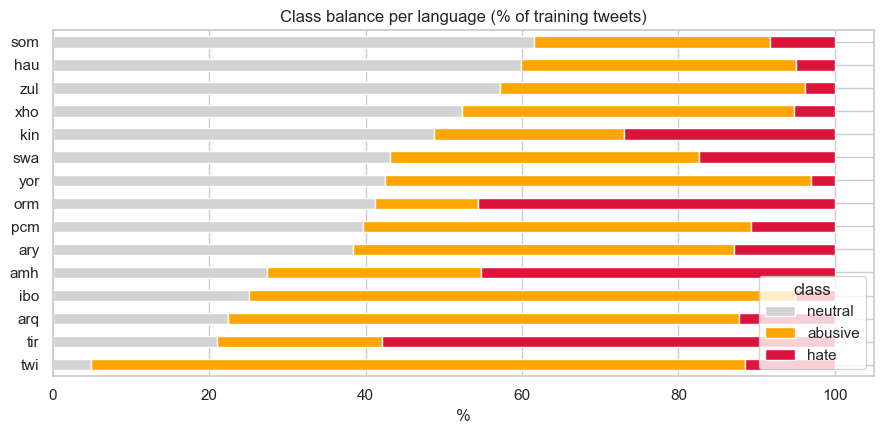

Split mode: general


,train,validation,test
category,,,
neutral,23855,5110,5112
abusive,23700,5078,5080
hate,10788,2314,2311
total,58343,12502,12503


In [36]:
# A first look at the clean data: how many tweets per class in each language?
counts = train.groupby(["lang", "category"]).size().unstack(fill_value=0)[LABELS]
(counts.div(counts.sum(axis=1), axis=0) * 100).sort_values("neutral").plot.barh(
    stacked=True, figsize=(9, 4.5), color=["lightgray", "orange", "crimson"])
plt.title("Class balance per language (% of training tweets)")
plt.xlabel("%"); plt.ylabel(""); plt.legend(title="class", loc="lower right")
plt.tight_layout(); plt.show()

# How big is each split, per class? (Every experiment uses exactly these three sets.)
split_summary = pd.DataFrame({"train": train["category"].value_counts(), "validation": validation["category"].value_counts(),
                              "test": test["category"].value_counts()}).loc[LABELS]
split_summary.loc["total"] = split_summary.sum()
print(f"Split mode: {SPLIT_MODE}")
split_summary

## 5. Helper functions (used by every experiment)

Two small helpers so that **every model is scored in exactly the same way**:

* `get_scores(y_true, probs)` → macro-F1, weighted-F1, accuracy, log loss
* `show_report(...)` → per-class report + confusion matrix

All models give **probabilities** (one per class) and the predicted class is the one with the highest probability.

In [37]:
def get_scores(y_true, probs):
    """Compute the 4 scores from predicted probabilities."""
    probs = np.clip(probs, 1e-12, 1.0)
    probs = probs / probs.sum(axis=1, keepdims=True)
    pred = probs.argmax(axis=1)
    classes = [0, 1, 2]
    return {"macro_f1": f1_score(y_true, pred, average="macro", labels=classes, zero_division=0),
            "weighted_f1": f1_score(y_true, pred, average="weighted", labels=classes, zero_division=0),
            "accuracy": accuracy_score(y_true, pred),
            "log_loss": log_loss(y_true, probs, labels=classes)}

def show_report(title, y_true, probs):
    """Per-class precision / recall / F1 and a confusion matrix."""
    pred = probs.argmax(axis=1)
    print(classification_report(y_true, pred, labels=[0, 1, 2], target_names=LABELS, zero_division=0, digits=3))
    plt.figure(figsize=(4.5, 3.6))
    sns.heatmap(confusion_matrix(y_true, pred, labels=[0, 1, 2]), annot=True, fmt="d", cmap="Blues",
                xticklabels=LABELS, yticklabels=LABELS, cbar=False)
    plt.title(title); plt.xlabel("predicted"); plt.ylabel("true")
    plt.tight_layout(); plt.show()

experiment_log = []      # one row per experiment, so we can compare everything at the end

def log_experiment(name, notes, settings, val_scores, cv_scores):
    experiment_log.append({"experiment": name, "notes": notes, "settings": str(settings),
                           "val_macro_f1": val_scores["macro_f1"], "val_log_loss": val_scores["log_loss"],
                           "cv_macro_f1": None if cv_scores is None else cv_scores["macro_f1_mean"]})

---
## Experiment 1: TF-IDF + Logistic Regression

**Idea:** turn each tweet into numbers with TF-IDF (single words *and* 2-word phrases) and learn which features point to which class.
**Class weights = "balanced":** mistakes on the rarer classes count more, which helps `hate` and `abusive`.

Run it by filling in `settings` and calling `run_experiment`.

In [38]:
settings = {"analyzer": "word", "ngram_range": (1, 2), "class_weight": "balanced", "C": 10.0}

def run_experiment(name, notes):
    """Train Logistic Regression with `settings`, then score it on validation and with 5-fold CV."""
    # 1. Build the model: TF-IDF features -> Logistic Regression
    model = make_pipeline(
        TfidfVectorizer(analyzer=settings["analyzer"], ngram_range=settings["ngram_range"], sublinear_tf=True, min_df=2),
        LogisticRegression(C=settings["C"], class_weight=settings["class_weight"], max_iter=300))

    # 2. Cross-validation on the TRAINING data (checks the score is stable)
    cv = cross_validate(model, train_text, y_train, cv=5, scoring="f1_macro", n_jobs=-1)
    cv_scores = {"macro_f1_mean": cv["test_score"].mean(), "macro_f1_std": cv["test_score"].std()}

    # 3. Train on the full training set and score on the VALIDATION set
    model.fit(train_text, y_train)
    val_probs = model.predict_proba(val_text)
    val_scores = get_scores(y_val, val_probs)

    log_experiment(name, notes, settings, val_scores, cv_scores)
    return model, val_probs, val_scores, cv_scores

lr_model, lr_val_probs, lr_val_scores, lr_cv_scores = run_experiment("word_bigrams_balanced", "Bigrams + class_weight=balanced.")
print("Validation:", {k: round(v, 4) for k, v in lr_val_scores.items()})
print(f"5-fold CV macro-F1: {lr_cv_scores['macro_f1_mean']:.4f} ± {lr_cv_scores['macro_f1_std']:.4f}")

Validation: {'macro_f1': 0.773, 'weighted_f1': 0.7836, 'accuracy': 0.7833, 'log_loss': 0.5437}
5-fold CV macro-F1: 0.7732 ± 0.0034


              precision    recall  f1-score   support

     neutral      0.784     0.808     0.796      5110
     abusive      0.817     0.779     0.798      5078
        hate      0.713     0.738     0.725      2314

    accuracy                          0.783     12502
   macro avg      0.772     0.775     0.773     12502
weighted avg      0.784     0.783     0.784     12502



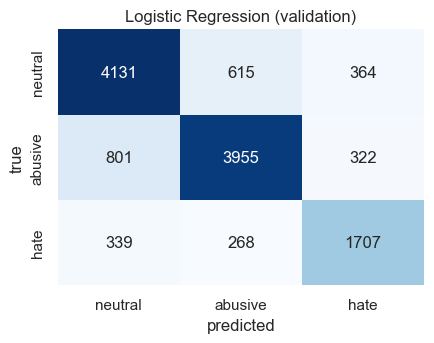

In [39]:
show_report("Logistic Regression (validation)", y_val, lr_val_probs)

---
## Experiment 2: TF-IDF + Complement Naive Bayes

**Idea:** count how often each word/phrase appears in each class and use Bayes' rule. It is the fastest model here.
**Complement NB** is a version designed for **imbalanced classes**. `alpha` is the smoothing strength (how much probability unseen words get).

In [40]:
settings = {"analyzer": "word", "ngram_range": (1, 2), "alpha": 0.1}

def run_experiment(name, notes):
    """Train Complement Naive Bayes with `settings`, then score it on validation and with 5-fold CV."""
    model = make_pipeline(
        TfidfVectorizer(analyzer=settings["analyzer"], ngram_range=settings["ngram_range"], min_df=2),
        ComplementNB(alpha=settings["alpha"]))

    cv = cross_validate(model, train_text, y_train, cv=5, scoring="f1_macro", n_jobs=-1)
    cv_scores = {"macro_f1_mean": cv["test_score"].mean(), "macro_f1_std": cv["test_score"].std()}

    model.fit(train_text, y_train)
    val_probs = model.predict_proba(val_text)
    val_scores = get_scores(y_val, val_probs)

    log_experiment(name, notes, settings, val_scores, cv_scores)
    return model, val_probs, val_scores, cv_scores

nb_model, nb_val_probs, nb_val_scores, nb_cv_scores = run_experiment("complement_nb_bigrams", "Complement NB, TF-IDF bigrams, alpha=0.1.")
print("Validation:", {k: round(v, 4) for k, v in nb_val_scores.items()})
print(f"5-fold CV macro-F1: {nb_cv_scores['macro_f1_mean']:.4f} ± {nb_cv_scores['macro_f1_std']:.4f}")

Validation: {'macro_f1': 0.7224, 'weighted_f1': 0.7324, 'accuracy': 0.7312, 'log_loss': 0.6643}
5-fold CV macro-F1: 0.7226 ± 0.0032


              precision    recall  f1-score   support

     neutral      0.791     0.676     0.729      5110
     abusive      0.753     0.768     0.761      5078
        hate      0.604     0.771     0.677      2314

    accuracy                          0.731     12502
   macro avg      0.716     0.738     0.722     12502
weighted avg      0.741     0.731     0.732     12502



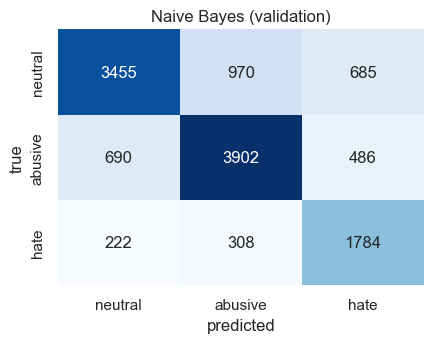

In [41]:
show_report("Naive Bayes (validation)", y_val, nb_val_probs)

---
## Tools for the two neural experiments (CNN and BiLSTM)

A neural network cannot read text, so we convert it step by step:

```
tweet  ->  words  ->  numbers (vocabulary)  ->  same length (pad/cut)  ->  network  ->  3 probabilities
```

This section prepares everything **once**:

1. `tokenize`: split a tweet into words (works for Latin, Ge'ez and Arabic scripts).
2. `vocab`: a dictionary word → number, built from **training tweets only**.
3. `NeuralTextClassifier`: a small wrapper so a neural model has the **same `.predict_proba(texts)`** as the scikit-learn models.
4. `train_network`: the training loop. After each epoch it checks validation macro-F1 and **keeps the best epoch** (early stopping).

In [42]:
PAD, UNK = 0, 1       # 0 = padding, 1 = unknown word

def tokenize(text):
    """Lower-case and split into words."""
    return re.findall(r"[\w'@#]+", str(text).lower())

# Build the vocabulary from TRAINING tweets only (words seen at least twice)
word_counts = Counter(word for text in train_text for word in tokenize(text))
vocab = {"<pad>": PAD, "<unk>": UNK}
for word, count in sorted(word_counts.items()):
    if count >= 2:
        vocab[word] = len(vocab)
print("Vocabulary size:", len(vocab))

def encode(texts, max_len):
    """Texts -> tensor of word numbers, all exactly max_len long."""
    rows = []
    for text in texts:
        ids = [vocab.get(word, UNK) for word in tokenize(text)[:max_len]]   # cut long tweets
        rows.append(ids + [PAD] * (max_len - len(ids)))                     # pad short tweets
    return torch.tensor(rows, dtype=torch.long)

class NeuralTextClassifier:
    """Wraps a trained network so it can be used like a scikit-learn model: model.predict_proba(texts)."""
    def __init__(self, network, max_len):
        self.network, self.max_len = network, max_len

    @torch.no_grad()
    def predict_proba(self, texts):
        self.network.eval()
        x = encode(texts, self.max_len)
        out = []
        for i in range(0, len(x), 512):                          # small batches to save memory
            logits = self.network(x[i:i + 512].to(device))
            out.append(F.softmax(logits, dim=1).cpu().numpy())
        return np.vstack(out)

Vocabulary size: 62557


In [43]:
def train_network(network, settings):
    """Train a network with Adam. Stops early when validation macro-F1 stops improving.
    Returns the best version of the network."""
    set_seed(SEED)
    network = network.to(device)
    x_train = encode(train_text, settings["max_len"])
    x_val = encode(val_text, settings["max_len"])

    # Class weights: rare classes get a bigger penalty when they are misclassified
    weights = None
    if settings["class_weights"]:
        w = compute_class_weight("balanced", classes=np.arange(3), y=y_train)
        weights = torch.tensor(w, dtype=torch.float32, device=device)
    loss_function = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.Adam(network.parameters(), lr=settings["lr"])
    loader = DataLoader(TensorDataset(x_train, torch.tensor(y_train)), batch_size=settings["batch_size"],
                        shuffle=True, generator=torch.Generator().manual_seed(SEED))

    best_f1, best_weights, epochs_without_gain, history = -1.0, None, 0, []
    for epoch in range(1, settings["epochs"] + 1):
        # ---- train for one epoch ----
        network.train()
        total_loss = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = loss_function(network(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(network.parameters(), 5.0)      # keeps training stable
            optimizer.step()
            total_loss += loss.item() * len(xb)

        # ---- check the validation set ----
        val_probs = NeuralTextClassifier(network, settings["max_len"]).predict_proba(val_text)
        val_f1 = f1_score(y_val, val_probs.argmax(axis=1), average="macro", labels=[0, 1, 2], zero_division=0)
        history.append((epoch, total_loss / len(y_train), val_f1))
        print(f"epoch {epoch:2d} | train loss {total_loss / len(y_train):.4f} | val macro-F1 {val_f1:.4f}")

        # ---- early stopping ----
        if val_f1 > best_f1 + 1e-4:
            best_f1, epochs_without_gain = val_f1, 0
            best_weights = {k: v.detach().clone() for k, v in network.state_dict().items()}
        else:
            epochs_without_gain += 1
            if epochs_without_gain >= settings["patience"]:
                print("Stopping early (no improvement).")
                break

    network.load_state_dict(best_weights)             # go back to the best epoch

    # Learning curve
    h = pd.DataFrame(history, columns=["epoch", "train_loss", "val_macro_f1"])
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot(h["epoch"], h["train_loss"]); ax[0].set_title("Training loss (should go down)")
    ax[1].plot(h["epoch"], h["val_macro_f1"]); ax[1].set_title("Validation macro-F1 (higher is better)")
    plt.tight_layout(); plt.show()
    return network

---
## Experiment 3: CNN

**Idea:** a 1D convolutional network slides small windows (3, 4 and 5 words wide) over the tweet. Each window detector learns to spot a **key phrase** (e.g. an insult). The strongest match of each detector is kept and used to classify. It is fast and works well on short texts like tweets.
**Class weights** are switched on so the rarer classes are not ignored.

epoch  1 | train loss 0.9231 | val macro-F1 0.6334
epoch  2 | train loss 0.7091 | val macro-F1 0.7045
epoch  3 | train loss 0.5659 | val macro-F1 0.7311
epoch  4 | train loss 0.4549 | val macro-F1 0.7356
epoch  5 | train loss 0.3659 | val macro-F1 0.7410
epoch  6 | train loss 0.2916 | val macro-F1 0.7430
epoch  7 | train loss 0.2252 | val macro-F1 0.7432
epoch  8 | train loss 0.1779 | val macro-F1 0.7400
epoch  9 | train loss 0.1406 | val macro-F1 0.7390
epoch 10 | train loss 0.1146 | val macro-F1 0.7348
epoch 11 | train loss 0.0940 | val macro-F1 0.7331
Stopping early (no improvement).


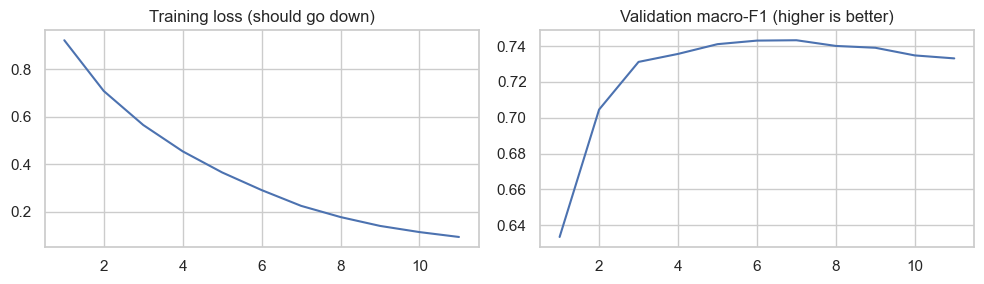

Validation: {'macro_f1': 0.7432, 'weighted_f1': 0.7554, 'accuracy': 0.7555, 'log_loss': 0.7834}


In [44]:
class TextCNN(nn.Module):
    """Words -> embeddings -> window detectors -> strongest match -> classifier."""
    def __init__(self, vocab_size, emb_dim, kernel_sizes, n_filters, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)     # word number -> vector
        self.convs = nn.ModuleList([nn.Conv1d(emb_dim, n_filters, k, padding=k // 2) for k in kernel_sizes])
        self.dropout = nn.Dropout(dropout)                                       # randomly switches off units (less overfitting)
        self.classifier = nn.Linear(n_filters * len(kernel_sizes), 3)

    def forward(self, x):
        x = self.embedding(x).transpose(1, 2)                                    # (batch, emb_dim, length)
        features = [F.relu(conv(x)).max(dim=2).values for conv in self.convs]    # strongest match per detector
        return self.classifier(self.dropout(torch.cat(features, dim=1)))

settings = {"max_len": 64, "emb_dim": 100, "kernel_sizes": (3, 4, 5), "n_filters": 100, "dropout": 0.5,
            "class_weights": True, "lr": 1e-3, "batch_size": 64, "epochs": 15, "patience": 4}

def run_experiment(name, notes):
    """Train the CNN with `settings` and score it on the validation set.
    cv_scores is None: cross-validating a neural network 5 times is too slow."""
    network = TextCNN(len(vocab), settings["emb_dim"], settings["kernel_sizes"], settings["n_filters"], settings["dropout"])
    network = train_network(network, settings)

    model = NeuralTextClassifier(network, settings["max_len"])
    val_probs = model.predict_proba(val_text)
    val_scores = get_scores(y_val, val_probs)
    cv_scores = None

    log_experiment(name, notes, settings, val_scores, cv_scores)
    return model, val_probs, val_scores, cv_scores

cnn_model, cnn_val_probs, cnn_val_scores, cnn_cv_scores = run_experiment("cnn_class_weights", "CNN, kernels 3/4/5, class weights.")
print("Validation:", {k: round(v, 4) for k, v in cnn_val_scores.items()})

              precision    recall  f1-score   support

     neutral      0.764     0.767     0.765      5110
     abusive      0.774     0.777     0.776      5078
        hate      0.694     0.683     0.689      2314

    accuracy                          0.755     12502
   macro avg      0.744     0.742     0.743     12502
weighted avg      0.755     0.755     0.755     12502



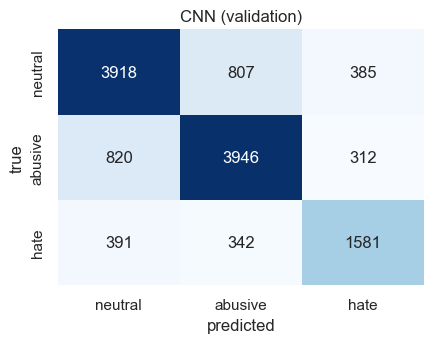

In [45]:
show_report("CNN (validation)", y_val, cnn_val_probs)

---
## Experiment 4: BiLSTM with attention

**Idea:** an LSTM reads the tweet word by word and remembers the context. **Bidirectional** means it reads forwards *and* backwards. Context matters in hate speech because the same word can be an insult or just a quote.
**Attention** lets the model learn *which words matter most* and focus on them, instead of treating all words the same.

In [ ]:
class BiLSTMAttention(nn.Module):
    """Words -> embeddings -> BiLSTM -> attention (weighted average) -> classifier."""
    def __init__(self, vocab_size, emb_dim, hidden, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.attention = nn.Sequential(nn.Linear(2 * hidden, 2 * hidden), nn.Tanh(), nn.Linear(2 * hidden, 1, bias=False))
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(2 * hidden, 3)

    def forward(self, x):
        is_word = (x != PAD)                                              # True for real words, False for padding
        lengths = is_word.sum(dim=1).clamp(min=1)
        embedded = self.dropout(self.embedding(x))

        # "Pack" the tweets so the LSTM ignores the padding
        packed = nn.utils.rnn.pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        output, _ = self.lstm(packed)
        output, _ = nn.utils.rnn.pad_packed_sequence(output, batch_first=True, total_length=x.size(1))

        # Attention: one score per word -> softmax gives weights that add up to 1
        scores = self.attention(output).squeeze(-1).masked_fill(~is_word, -1e9)
        weights = F.softmax(scores, dim=1)
        summary = (weights.unsqueeze(-1) * output).sum(dim=1)             # weighted average of the words
        return self.classifier(self.dropout(summary))

settings = {"max_len": 64, "emb_dim": 100, "hidden": 64, "dropout": 0.4,
            "class_weights": True, "lr": 1e-3, "batch_size": 64, "epochs": 15, "patience": 4}

def run_experiment(name, notes):
    """Train the BiLSTM with `settings` and score it on the validation set (cv_scores is None, as for the CNN)."""
    network = BiLSTMAttention(len(vocab), settings["emb_dim"], settings["hidden"], settings["dropout"])
    network = train_network(network, settings)

    model = NeuralTextClassifier(network, settings["max_len"])
    val_probs = model.predict_proba(val_text)
    val_scores = get_scores(y_val, val_probs)
    cv_scores = None

    log_experiment(name, notes, settings, val_scores, cv_scores)
    return model, val_probs, val_scores, cv_scores

bilstm_model, bilstm_val_probs, bilstm_val_scores, bilstm_cv_scores = run_experiment("bilstm_attention_class_weights", "BiLSTM + attention + class weights.")
print("Validation:", {k: round(v, 4) for k, v in bilstm_val_scores.items()})

In [ ]:
show_report("BiLSTM + attention (validation)", y_val, bilstm_val_probs)

---
## Bonus experiment 5: Ensemble

**Idea:** different models make different mistakes. If we **average their probabilities**, many mistakes cancel out. No new training is needed.

In [ ]:
class AverageEnsemble:
    """Averages the probabilities of several models."""
    def __init__(self, models):
        self.models = models
    def predict_proba(self, texts):
        return np.mean([m.predict_proba(texts) for m in self.models], axis=0)

ensemble_model = AverageEnsemble([lr_model, nb_model, cnn_model, bilstm_model])
ensemble_val_probs = ensemble_model.predict_proba(val_text)
ensemble_val_scores = get_scores(y_val, ensemble_val_probs)
log_experiment("ensemble_of_4", "Average of LR, NB, CNN and BiLSTM probabilities.", {}, ensemble_val_scores, None)
print("Validation:", {k: round(v, 4) for k, v in ensemble_val_scores.items()})

---
## 6. Compare all experiments on the validation set

We pick the best model with **validation macro-F1** (the test set is still untouched).

In [ ]:
log_table = pd.DataFrame(experiment_log).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
display(log_table.drop(columns=["settings"]).round(4))

best_name = log_table.loc[0, "experiment"]
print(f"🏆 Best on validation: {best_name}")

plt.figure(figsize=(8, 3.5))
colors = ["seagreen" if n == best_name else "steelblue" for n in log_table["experiment"]]
plt.barh(log_table["experiment"], log_table["val_macro_f1"], color=colors)
plt.gca().invert_yaxis(); plt.xlabel("validation macro-F1 (higher is better)")
plt.title("All experiments on the validation set")
plt.tight_layout(); plt.show()

---
## 7. Final test (used only once!)

Now, and only now, we score every model on the **test set**. We also look at each **language** separately, because a multilingual model can be good in one language and weak in another.

In [ ]:
final_models = {"logistic_regression": lr_model, "naive_bayes": nb_model, "cnn": cnn_model,
                "bilstm_attention": bilstm_model, "ensemble": ensemble_model}
experiment_to_model = {"word_bigrams_balanced": "logistic_regression", "complement_nb_bigrams": "naive_bayes",
                       "cnn_class_weights": "cnn", "bilstm_attention_class_weights": "bilstm_attention",
                       "ensemble_of_4": "ensemble"}
best_model_name = experiment_to_model[best_name]

test_probs = {name: model.predict_proba(test_text) for name, model in final_models.items()}

test_table = pd.DataFrame({name: get_scores(y_test, probs) for name, probs in test_probs.items()}).T
display(test_table.sort_values("macro_f1", ascending=False).round(4))
print(f"Chosen on validation: {best_model_name}")

In [ ]:
# Macro-F1 per language (rows = languages, columns = models)
def macro_f1_per_language(probs):
    pred = probs.argmax(axis=1)
    return pd.Series({lang: f1_score(y_test[lang_test == lang], pred[lang_test == lang], average="macro",
                                     labels=[0, 1, 2], zero_division=0) for lang in sorted(set(lang_test))})

per_language = pd.DataFrame({name: macro_f1_per_language(p) for name, p in test_probs.items()})
per_language.index = [f"{c} ({LANGUAGE_NAMES.get(c, c)})" for c in per_language.index]

plt.figure(figsize=(8, 0.45 * len(per_language) + 2))
sns.heatmap(per_language, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Test macro-F1 per language"); plt.ylabel("")
plt.tight_layout(); plt.show()

In [ ]:
# Detailed look at the model we chose on validation
show_report(f"{best_model_name} (test)", y_test, test_probs[best_model_name])

In [ ]:
# Save the tables
out = ROOT / "results_afrihate"; out.mkdir(exist_ok=True)
log_table.to_csv(out / "experiment_log.csv", index=False)
test_table.to_csv(out / "test_scores.csv")
per_language.to_csv(out / "test_macro_f1_per_language.csv")
print("Saved in:", out.resolve())

In [ ]:
# ── Print ALL results in one place (and save them to a text file) ──────────
report_lines = []
def say(text=""):
    print(text)
    report_lines.append(str(text))

def section(title):
    say("\n" + "=" * 72); say(title); say("=" * 72)

# 1. The data
section("1. DATA")
say(f"Split mode: {SPLIT_MODE}")
say(language_check.to_string())
say()
say(split_summary.to_string())

# 2. Every experiment that was run
section("2. ALL EXPERIMENTS (validation set, best first)")
say(log_table.drop(columns=["settings"]).round(4).to_string())
say()
for row in experiment_log:
    say(f"- {row['experiment']}: {row['notes']}")
    say(f"    settings: {row['settings']}")

# 3. Validation scores and cross-validation scores of each model
section("3. VALIDATION AND CROSS-VALIDATION SCORES")
all_val_scores = {"logistic_regression": lr_val_scores, "naive_bayes": nb_val_scores, "cnn": cnn_val_scores,
                  "bilstm_attention": bilstm_val_scores, "ensemble": ensemble_val_scores}
all_cv_scores = {"logistic_regression": lr_cv_scores, "naive_bayes": nb_cv_scores, "cnn": cnn_cv_scores,
                 "bilstm_attention": bilstm_cv_scores, "ensemble": None}
for name in all_val_scores:
    v, cv = all_val_scores[name], all_cv_scores[name]
    say(f"{name:20s} validation: macro-F1 {v['macro_f1']:.4f} | weighted-F1 {v['weighted_f1']:.4f} | "
        f"accuracy {v['accuracy']:.4f} | log loss {v['log_loss']:.4f}")
    say(f"{'':20s} 5-fold CV macro-F1: " + (f"{cv['macro_f1_mean']:.4f} ± {cv['macro_f1_std']:.4f}" if cv else "not run"))

# 4. Test scores
section("4. TEST SCORES (the test set was used only once)")
say(test_table.sort_values("macro_f1", ascending=False).round(4).to_string())
say()
say(f"Chosen on validation: {best_model_name}")

# 5. Per-class report of every model on the test set
section("5. PER-CLASS REPORT ON THE TEST SET (every model)")
for name, probs in test_probs.items():
    say(f"\n--- {name}")
    say(classification_report(y_test, probs.argmax(axis=1), labels=[0, 1, 2], target_names=LABELS,
                              zero_division=0, digits=3))

# 6. Per-language results
section("6. TEST MACRO-F1 PER LANGUAGE")
say(per_language.round(3).to_string())

# Save everything to a text file
out = ROOT / "results_afrihate"; out.mkdir(exist_ok=True)
(out / "all_results.txt").write_text("\n".join(report_lines), encoding="utf-8")
say(f"\nAll of the above was also saved to: {(out / 'all_results.txt').resolve()}")

---
## How to read the results

* **Use macro-F1, not accuracy.** If most tweets are neutral, a model can have high accuracy and still miss hate speech.
* **Look at each language.** One overall number can hide weak languages.
* **Hate and abusive overlap.** Even human annotators confuse them, so some confusion is normal.
* **To improve a model:** change the numbers in its `settings` dictionary, re-run that one experiment and compare the validation macro-F1 in Section 3.